# 11. Final Model Validation and Freeze

## Objective

This notebook performs the final validation and freezing of the employability prediction model before system integration.

The objectives are to:

- validate candidate models using nested cross-validation;
- select the final model based only on cross-validated performance;
- examine prediction errors and model stability;
- fit the selected model using the full development dataset;
- calculate final SHAP thresholds for the recommendation system;
- freeze the prediction model and recommendation configuration for deployment.

Nested cross-validation is used as the primary final validation method because model performance on the earlier hold-out set was already inspected during the exploratory model-development stage.

In [70]:
from pathlib import Path
from datetime import datetime
import json
import hashlib
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

In [71]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_FILE = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "descriptive_dataset.csv"
)

MODEL_DIR = PROJECT_DIR / "models"

VALIDATION_DIR = (
    PROJECT_DIR
    / "reports"
    / "final_validation"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project Directory:")
print(PROJECT_DIR)

print("\nDataset:")
print(DATA_FILE)

Project Directory:
d:\internship-employability-project

Dataset:
d:\internship-employability-project\data\processed\descriptive_dataset.csv


In [72]:
df = pd.read_csv(
    DATA_FILE
)

print(
    "Dataset shape:",
    df.shape
)

df.head()

Dataset shape: (1000, 29)


,Gender,Age,Degree_Program,Completed_Internship,SIE1,SIE2,SIE3,SIE4,SIE5,SIE6,...,EMP4,EMP5,EMP6,EMP7,EMP8,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
0,Male,24–26,Engineering,Yes,4,5,4,4,5,5,...,4,4,4,5,5,4.25,5.0,4.25,4.5,4.625
1,Male,21–23,Information Technology,Yes,5,4,4,4,4,4,...,4,3,5,4,4,4.25,4.0,3.75,3.5,3.875
2,Male,21–23,Information Technology,Yes,4,5,4,4,4,3,...,4,4,5,4,3,4.25,3.5,4.00,4.0,3.875
3,Female,18–20,Engineering,Yes,4,4,4,4,4,3,...,4,4,4,4,4,4.00,3.5,3.75,3.0,4.000
4,Prefer not to say,18–20,Other,Yes,4,5,4,4,4,5,...,4,5,5,4,4,4.25,4.5,4.25,4.5,4.250


Define final research features

In [73]:
feature_names = [
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

target_name = (
    "Employability_Score"
)

X = df[
    feature_names
].copy()

y = df[
    target_name
].copy()

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

X shape: (1000, 4)
y shape: (1000,)


Final data-quality check

In [74]:
print(
    "Missing feature values:",
    X.isnull().sum().sum()
)

print(
    "Missing target values:",
    y.isnull().sum()
)

print(
    "\nTarget minimum:",
    y.min()
)

print(
    "Target maximum:",
    y.max()
)

Missing feature values: 0
Missing target values: 0

Target minimum: 1.0
Target maximum: 5.0


In [75]:
assert (
    X.isnull().sum().sum()
    == 0
)

assert (
    y.isnull().sum()
    == 0
)

print(
    "\nFinal dataset validation passed."
)


Final dataset validation passed.


Define candidate models

In [76]:
linear_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

In [77]:
rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

In [78]:
xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1,
    verbosity=0
)

Define tuning spaces

In [79]:
rf_param_dist = {

    "n_estimators": [
        100,
        200,
        300,
        500
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        4,
        6
    ],

    "max_features": [
        "sqrt",
        0.5,
        1.0
    ],

    "bootstrap": [
        True
    ]
}

In [80]:
xgb_param_dist = {

    "n_estimators": [
        200,
        300,
        500,
        700
    ],

    "learning_rate": [
        0.01,
        0.03,
        0.05,
        0.10
    ],

    "max_depth": [
        2,
        3,
        4,
        5,
        6
    ],

    "min_child_weight": [
        1,
        2,
        4,
        6
    ],

    "subsample": [
        0.6,
        0.7,
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.6,
        0.8,
        1.0
    ],

    "reg_alpha": [
        0,
        0.01,
        0.1,
        0.5
    ],

    "reg_lambda": [
        1,
        2,
        5,
        10
    ]
}

Define Nested Cross-Validation

In [81]:
outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

## Nested Cross-Validation

Nested cross-validation separates hyperparameter optimization from model evaluation.

The inner five-fold cross-validation loop is used to optimize model hyperparameters, while the outer five-fold loop evaluates how well the resulting model generalizes to unseen observations.

This reduces optimistic bias that can occur when the same validation results are repeatedly used for both tuning and evaluation.

Create metric function

In [82]:
def calculate_regression_metrics(
    y_true,
    y_pred
):

    r2 = r2_score(
        y_true,
        y_pred
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    return {
        "R2": float(r2),
        "MAE": float(mae),
        "RMSE": float(rmse)
    }

Prepare nested CV storage

In [83]:
nested_results = []

oof_predictions = {

    "Linear Regression":
        np.full(
            len(X),
            np.nan
        ),

    "Random Forest":
        np.full(
            len(X),
            np.nan
        ),

    "XGBoost":
        np.full(
            len(X),
            np.nan
        )
}

best_parameter_log = {
    "Random Forest": [],
    "XGBoost": []
}

Run Nested Cross-Validation

In [84]:
for fold_number, (
    train_index,
    validation_index
) in enumerate(
    outer_cv.split(
        X,
        y
    ),
    start=1
):

    print(
        f"\nRunning outer fold "
        f"{fold_number}/5"
    )

    X_outer_train = X.iloc[
        train_index
    ]

    X_outer_valid = X.iloc[
        validation_index
    ]

    y_outer_train = y.iloc[
        train_index
    ]

    y_outer_valid = y.iloc[
        validation_index
    ]

    # =====================================================
    # LINEAR REGRESSION
    # =====================================================

    lr_model = clone(
        linear_model
    )

    lr_model.fit(
        X_outer_train,
        y_outer_train
    )

    lr_prediction = (
        lr_model.predict(
            X_outer_valid
        )
    )

    oof_predictions[
        "Linear Regression"
    ][validation_index] = (
        lr_prediction
    )

    lr_metrics = (
        calculate_regression_metrics(
            y_outer_valid,
            lr_prediction
        )
    )

    nested_results.append({

        "Fold":
            fold_number,

        "Model":
            "Linear Regression",

        **lr_metrics
    })

    # =====================================================
    # RANDOM FOREST
    # =====================================================

    rf_search = RandomizedSearchCV(

        estimator=clone(
            rf_base
        ),

        param_distributions=
            rf_param_dist,

        n_iter=20,

        scoring="r2",

        cv=inner_cv,

        random_state=(
            42
            + fold_number
        ),

        n_jobs=-1,

        refit=True
    )

    rf_search.fit(
        X_outer_train,
        y_outer_train
    )

    rf_best = (
        rf_search.best_estimator_
    )

    rf_prediction = (
        rf_best.predict(
            X_outer_valid
        )
    )

    oof_predictions[
        "Random Forest"
    ][validation_index] = (
        rf_prediction
    )

    rf_metrics = (
        calculate_regression_metrics(
            y_outer_valid,
            rf_prediction
        )
    )

    nested_results.append({

        "Fold":
            fold_number,

        "Model":
            "Random Forest",

        **rf_metrics
    })

    best_parameter_log[
        "Random Forest"
    ].append(
        rf_search.best_params_
    )

    # =====================================================
    # XGBOOST
    # =====================================================

    xgb_search = RandomizedSearchCV(

        estimator=clone(
            xgb_base
        ),

        param_distributions=
            xgb_param_dist,

        n_iter=20,

        scoring="r2",

        cv=inner_cv,

        random_state=(
            100
            + fold_number
        ),

        n_jobs=-1,

        refit=True
    )

    xgb_search.fit(
        X_outer_train,
        y_outer_train
    )

    xgb_best = (
        xgb_search.best_estimator_
    )

    xgb_prediction = (
        xgb_best.predict(
            X_outer_valid
        )
    )

    oof_predictions[
        "XGBoost"
    ][validation_index] = (
        xgb_prediction
    )

    xgb_metrics = (
        calculate_regression_metrics(
            y_outer_valid,
            xgb_prediction
        )
    )

    nested_results.append({

        "Fold":
            fold_number,

        "Model":
            "XGBoost",

        **xgb_metrics
    })

    best_parameter_log[
        "XGBoost"
    ].append(
        xgb_search.best_params_
    )

print(
    "\nNested cross-validation complete."
)


Running outer fold 1/5

Running outer fold 2/5

Running outer fold 3/5

Running outer fold 4/5

Running outer fold 5/5

Nested cross-validation complete.


Create Nested CV results table

In [85]:
nested_results_df = (
    pd.DataFrame(
        nested_results
    )
)

nested_results_df

,Fold,Model,R2,MAE,RMSE
0,1,Linear Regression,0.442780,0.190663,0.296862
1,1,Random Forest,0.417301,0.180642,0.303573
2,1,XGBoost,0.432474,0.184392,0.299594
3,2,Linear Regression,0.355476,0.175172,0.246531
4,2,Random Forest,0.368529,0.166924,0.244022
5,2,XGBoost,0.396694,0.168219,0.238518
6,3,Linear Regression,0.440904,0.190932,0.305186
7,3,Random Forest,0.488046,0.175429,0.292036
8,3,XGBoost,0.533725,0.171948,0.278703
9,4,Linear Regression,0.610878,0.160755,0.233970


Calculate final CV summary

In [86]:
nested_summary = (

    nested_results_df

    .groupby(
        "Model"
    )

    .agg(

        Mean_R2=(
            "R2",
            "mean"
        ),

        R2_Std=(
            "R2",
            "std"
        ),

        Mean_MAE=(
            "MAE",
            "mean"
        ),

        MAE_Std=(
            "MAE",
            "std"
        ),

        Mean_RMSE=(
            "RMSE",
            "mean"
        ),

        RMSE_Std=(
            "RMSE",
            "std"
        )
    )

    .reset_index()
)

nested_summary = (
    nested_summary.sort_values(
        "Mean_R2",
        ascending=False
    )
)

nested_summary

,Model,Mean_R2,R2_Std,Mean_MAE,MAE_Std,Mean_RMSE,RMSE_Std
2,XGBoost,0.460990,0.051102,0.171602,0.009410,0.269425,0.022863
0,Linear Regression,0.458872,0.092992,0.180710,0.012852,0.269303,0.030994
1,Random Forest,0.454756,0.076417,0.169275,0.011137,0.270608,0.026690


Visualize CV R²

<Figure size 800x500 with 0 Axes>

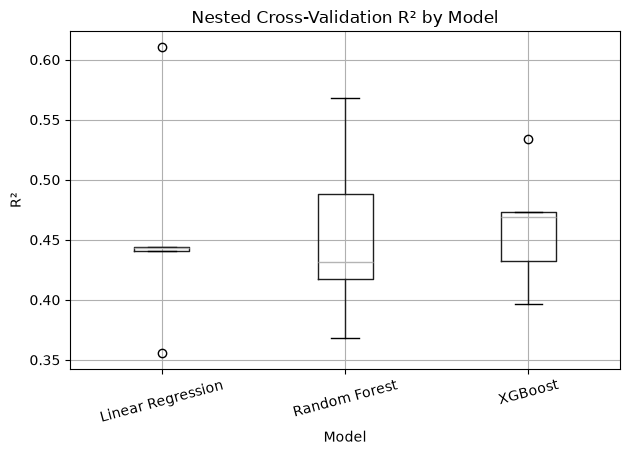

In [87]:
plt.figure(
    figsize=(8, 5)
)

nested_results_df.boxplot(
    column="R2",
    by="Model"
)

plt.title(
    "Nested Cross-Validation R² by Model"
)

plt.suptitle("")

plt.ylabel(
    "R²"
)

plt.xlabel(
    "Model"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.show()

Select final model using a predefined rule

In [88]:
best_mean_r2 = (
    nested_summary[
        "Mean_R2"
    ].max()
)

competitive_models = (
    nested_summary[
        nested_summary[
            "Mean_R2"
        ]
        >=
        (
            best_mean_r2
            - 0.01
        )
    ]
)

competitive_models

,Model,Mean_R2,R2_Std,Mean_MAE,MAE_Std,Mean_RMSE,RMSE_Std
2,XGBoost,0.460990,0.051102,0.171602,0.009410,0.269425,0.022863
0,Linear Regression,0.458872,0.092992,0.180710,0.012852,0.269303,0.030994
1,Random Forest,0.454756,0.076417,0.169275,0.011137,0.270608,0.026690


In [89]:
selected_row = (

    competitive_models

    .sort_values(
        [
            "R2_Std",
            "Mean_RMSE",
            "Mean_MAE"
        ],
        ascending=[
            True,
            True,
            True
        ]
    )

    .iloc[0]
)

selected_model_name = (
    selected_row[
        "Model"
    ]
)

print(
    "Selected final model:",
    selected_model_name
)

Selected final model: XGBoost


Verify OOF predictions

In [90]:
for model_name, predictions in (
    oof_predictions.items()
):

    missing_count = (
        np.isnan(
            predictions
        ).sum()
    )

    print(
        model_name,
        "missing OOF predictions:",
        missing_count
    )

Linear Regression missing OOF predictions: 0
Random Forest missing OOF predictions: 0
XGBoost missing OOF predictions: 0


Final out-of-fold error analysis

In [91]:
selected_oof_predictions = (
    oof_predictions[
        selected_model_name
    ]
)

In [92]:
error_analysis = pd.DataFrame({

    "Original Row Index":
        X.index,

    "Actual Employability Score":
        y.values,

    "OOF Predicted Score":
        selected_oof_predictions
})

In [93]:
error_analysis[
    "Residual"
] = (
    error_analysis[
        "Actual Employability Score"
    ]
    -
    error_analysis[
        "OOF Predicted Score"
    ]
)

error_analysis[
    "Absolute Error"
] = np.abs(
    error_analysis[
        "Residual"
    ]
)

error_analysis.head()

,Original Row Index,Actual Employability Score,OOF Predicted Score,Residual,Absolute Error
0,0,4.625,4.298093,0.326907,0.326907
1,1,3.875,4.119090,-0.244090,0.244090
2,2,3.875,4.118534,-0.243534,0.243534
3,3,4.000,3.899109,0.100891,0.100891
4,4,4.250,4.295588,-0.045588,0.045588


Calculate overall OOF performance

In [94]:
final_oof_metrics = (
    calculate_regression_metrics(
        y,
        selected_oof_predictions
    )
)

final_oof_metrics

{'R2': 0.4686142754818975,
 'MAE': 0.17160207390785218,
 'RMSE': 0.2701999376640529}

Check largest prediction errors

In [95]:
largest_errors = (

    error_analysis

    .sort_values(
        "Absolute Error",
        ascending=False
    )

    .head(10)
)

largest_errors

,Original Row Index,Actual Employability Score,OOF Predicted Score,Residual,Absolute Error
94,94,2.125,4.005458,-1.880458,1.880458
213,213,1.000,2.870098,-1.870098,1.870098
36,36,2.875,4.221562,-1.346562,1.346562
170,170,2.875,4.188465,-1.313465,1.313465
184,184,4.875,3.575549,1.299451,1.299451
43,43,2.375,3.622197,-1.247197,1.247197
262,262,2.625,3.870636,-1.245636,1.245636
210,210,4.625,3.381842,1.243158,1.243158
24,24,4.375,3.263865,1.111135,1.111135
119,119,3.750,4.791312,-1.041312,1.041312


Error by outcome quartile

In [96]:
error_analysis[
    "Actual Score Quartile"
] = pd.qcut(

    error_analysis[
        "Actual Employability Score"
    ],

    q=4,

    labels=[
        "Q1 - Lower",
        "Q2",
        "Q3",
        "Q4 - Higher"
    ],

    duplicates="drop"
)

In [97]:
quartile_error = (

    error_analysis

    .groupby(
        "Actual Score Quartile",
        observed=False
    )

    .agg(

        Students=(
            "Actual Employability Score",
            "count"
        ),

        MAE=(
            "Absolute Error",
            "mean"
        )
    )

    .reset_index()
)

quartile_error

,Actual Score Quartile,Students,MAE
0,Q1 - Lower,469,0.180129
1,Q2,102,0.133806
2,Q3,340,0.132223
3,Q4 - Higher,89,0.320420


Actual vs predicted plot

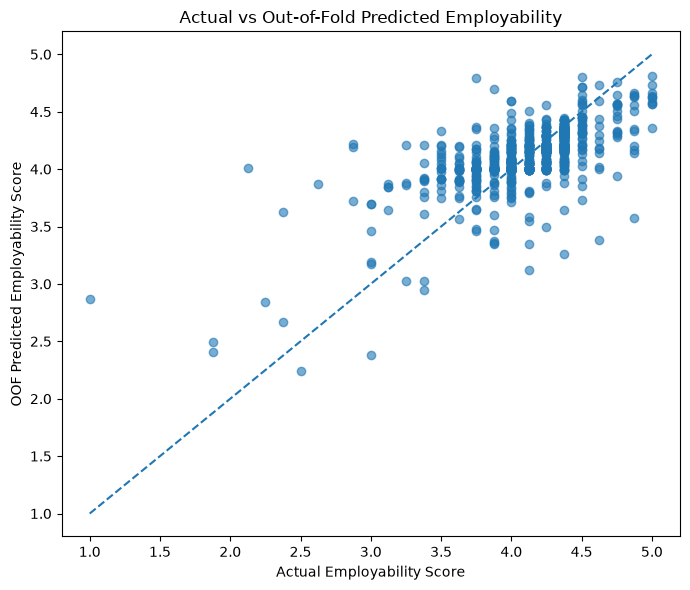

In [98]:
plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    error_analysis[
        "Actual Employability Score"
    ],
    error_analysis[
        "OOF Predicted Score"
    ],
    alpha=0.6
)

minimum_value = min(
    error_analysis[
        "Actual Employability Score"
    ].min(),
    error_analysis[
        "OOF Predicted Score"
    ].min()
)

maximum_value = max(
    error_analysis[
        "Actual Employability Score"
    ].max(),
    error_analysis[
        "OOF Predicted Score"
    ].max()
)

plt.plot(
    [
        minimum_value,
        maximum_value
    ],
    [
        minimum_value,
        maximum_value
    ],
    linestyle="--"
)

plt.xlabel(
    "Actual Employability Score"
)

plt.ylabel(
    "OOF Predicted Employability Score"
)

plt.title(
    "Actual vs Out-of-Fold Predicted Employability"
)

plt.tight_layout()

plt.show()

Residual plot

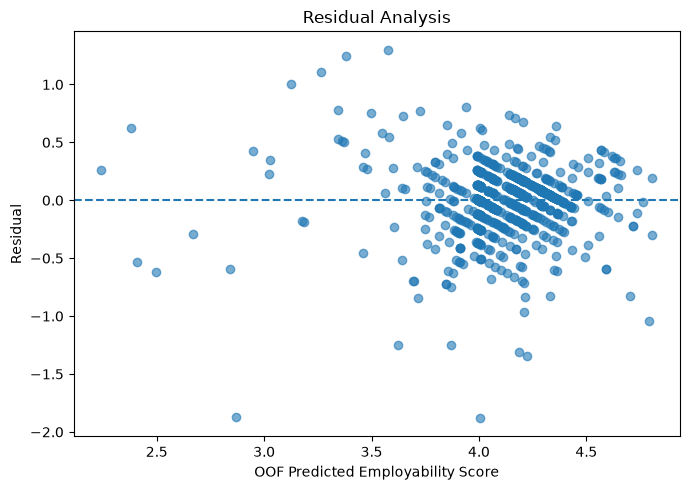

In [99]:
plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    error_analysis[
        "OOF Predicted Score"
    ],
    error_analysis[
        "Residual"
    ],
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "OOF Predicted Employability Score"
)

plt.ylabel(
    "Residual"
)

plt.title(
    "Residual Analysis"
)

plt.tight_layout()

plt.show()

Now tune the selected model on the FULL dataset

In [100]:
if selected_model_name == "Random Forest":

    final_search = RandomizedSearchCV(

        estimator=clone(
            rf_base
        ),

        param_distributions=
            rf_param_dist,

        n_iter=30,

        scoring="r2",

        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        ),

        random_state=42,

        n_jobs=-1,

        refit=True
    )

    final_search.fit(
        X,
        y
    )

    final_model = (
        final_search.best_estimator_
    )

    final_best_params = (
        final_search.best_params_
    )

In [ ]:
print("Selected final model:", selected_model_name)

Selected final model: XGBoost


In [103]:
if selected_model_name == "Random Forest":

    final_search = RandomizedSearchCV(
        estimator=clone(
            rf_base
        ),
        param_distributions=
            rf_param_dist,
        n_iter=30,
        scoring="r2",
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        ),
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    final_search.fit(
        X,
        y
    )

    final_model = (
        final_search.best_estimator_
    )

    final_best_params = (
        final_search.best_params_
    )


elif selected_model_name == "XGBoost":

    final_search = RandomizedSearchCV(
        estimator=clone(
            xgb_base
        ),
        param_distributions=
            xgb_param_dist,
        n_iter=30,
        scoring="r2",
        cv=KFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        ),
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    final_search.fit(
        X,
        y
    )

    final_model = (
        final_search.best_estimator_
    )

    final_best_params = (
        final_search.best_params_
    )


elif selected_model_name == "Linear Regression":

    final_model = clone(
        linear_model
    )

    final_model.fit(
        X,
        y
    )

    final_best_params = (
        final_model.get_params()
    )


else:

    raise ValueError(
        f"Unknown selected model: "
        f"{selected_model_name}"
    )


print(
    "Final model:",
    selected_model_name
)

print(
    "\nFinal parameters:"
)

print(
    final_best_params
)

Final model: XGBoost

Final parameters:
{'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0.01, 'n_estimators': 500, 'min_child_weight': 4, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


Generate SHAP values for final model

In [104]:
if selected_model_name in [
    "Random Forest",
    "XGBoost"
]:

    final_explainer = (
        shap.TreeExplainer(
            final_model
        )
    )

    final_shap_values = (
        final_explainer(
            X
        )
    )

In [105]:
if selected_model_name in [
    "Random Forest",
    "XGBoost"
]:

    final_explainer = shap.TreeExplainer(
        final_model
    )

    final_shap_values = final_explainer(
        X
    )

print(
    "Final SHAP shape:",
    final_shap_values.values.shape
)

Final SHAP shape: (1000, 4)


Freeze final SHAP thresholds

In [106]:
absolute_shap_values = np.abs(
    final_shap_values.values
).flatten()

In [107]:
final_small_shap_threshold = (
    np.quantile(
        absolute_shap_values,
        0.50
    )
)

In [108]:
final_small_shap_threshold = (
    np.quantile(
        absolute_shap_values,
        0.50
    )
)

In [109]:
final_large_shap_threshold = (
    np.quantile(
        absolute_shap_values,
        0.75
    )
)

In [110]:
print(
    "Final small SHAP threshold:",
    round(
        float(
            final_small_shap_threshold
        ),
        4
    )
)

print(
    "Final large SHAP threshold:",
    round(
        float(
            final_large_shap_threshold
        ),
        4
    )
)

Final small SHAP threshold: 0.0268
Final large SHAP threshold: 0.0769


Save final model

In [111]:
FINAL_MODEL_FILE = (
    MODEL_DIR
    / "final_employability_model.joblib"
)

joblib.dump(
    final_model,
    FINAL_MODEL_FILE
)

print(
    "Final model saved:"
)

print(
    FINAL_MODEL_FILE
)

Final model saved:
d:\internship-employability-project\models\final_employability_model.joblib


Verify saved model

In [112]:
reloaded_model = joblib.load(
    FINAL_MODEL_FILE
)

In [113]:
original_predictions = (
    final_model.predict(
        X.head(10)
    )
)

reloaded_predictions = (
    reloaded_model.predict(
        X.head(10)
    )
)

model_reload_valid = np.allclose(
    original_predictions,
    reloaded_predictions
)

print(
    "Model reload validation:",
    model_reload_valid
)

Model reload validation: True


Load existing recommendation configuration

In [114]:
OLD_CONFIG_FILE = (
    MODEL_DIR
    / "recommendation_system_config.json"
)

In [115]:
if OLD_CONFIG_FILE.exists():

    with open(
        OLD_CONFIG_FILE,
        "r",
        encoding="utf-8"
    ) as file:

        recommendation_config = (
            json.load(
                file
            )
        )

else:

    recommendation_config = {}

Update and freeze recommendation config

In [116]:
recommendation_config.update({

    "model_name":
        selected_model_name,

    "features":
        feature_names,

    "small_shap_threshold":
        float(
            final_small_shap_threshold
        ),

    "large_shap_threshold":
        float(
            final_large_shap_threshold
        ),

    "maximum_priority_constructs":
        2,

    "recommendation_method":
        (
            "Construct Score + "
            "Local SHAP Hybrid Logic"
        ),

    "validation_status":
        (
            "Technical prototype validated; "
            "expert content validation pending"
        ),

    "model_validation":
        "Nested 5x5 cross-validation",

    "frozen_at":
        datetime.now().isoformat()
})

In [117]:
FROZEN_CONFIG_FILE = (
    MODEL_DIR
    / "recommendation_system_config_frozen.json"
)

with open(
    FROZEN_CONFIG_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        recommendation_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    "Frozen recommendation config saved."
)

Frozen recommendation config saved.


Save final validation results

In [118]:
nested_results_df.to_csv(
    VALIDATION_DIR
    / "Nested_CV_Fold_Results.csv",
    index=False
)

nested_summary.to_csv(
    VALIDATION_DIR
    / "Nested_CV_Model_Summary.csv",
    index=False
)

error_analysis.to_csv(
    VALIDATION_DIR
    / "Final_OOF_Error_Analysis.csv",
    index=False
)

largest_errors.to_csv(
    VALIDATION_DIR
    / "Largest_Prediction_Errors.csv",
    index=False
)

quartile_error.to_csv(
    VALIDATION_DIR
    / "Error_By_Outcome_Quartile.csv",
    index=False
)

Save final metadata

In [119]:
model_metadata = {

    "model_name":
        selected_model_name,

    "features":
        feature_names,

    "target":
        target_name,

    "dataset_size":
        int(
            len(df)
        ),

    "validation_method":
        "5x5 Nested Cross-Validation",

    "final_oof_metrics":
        final_oof_metrics,

    "final_model_parameters":
        final_best_params,

    "small_shap_threshold":
        float(
            final_small_shap_threshold
        ),

    "large_shap_threshold":
        float(
            final_large_shap_threshold
        ),

    "recommendation_status":
        (
            "Prototype recommendation mapping "
            "pending expert validation"
        ),

    "data_status":
        (
            "Synthetic development dataset"
        )
}

In [120]:
METADATA_FILE = (
    MODEL_DIR
    / "final_model_metadata.json"
)

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4,
        default=str
    )

print(
    "Final metadata saved."
)

Final metadata saved.


Optional but useful: create file hashes

In [121]:
def calculate_sha256(
    file_path
):

    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        while True:

            block = file.read(
                8192
            )

            if not block:
                break

            sha256.update(
                block
            )

    return sha256.hexdigest()

In [122]:
print(
    "Model SHA256:"
)

print(
    calculate_sha256(
        FINAL_MODEL_FILE
    )
)

print(
    "\nConfig SHA256:"
)

print(
    calculate_sha256(
        FROZEN_CONFIG_FILE
    )
)

Model SHA256:
2629feeaaf1bb3059bddc942f4c0a2e8170564a2288f9b571bc7ea95d2b29bc0

Config SHA256:
5494b8b227fb5d05d01ac3331900dd9ae89ee2dad3b66bd475a247f26ad4c92b


## Final Model Validation

Final model validation was conducted using nested five-fold cross-validation. The outer cross-validation loop was used to estimate generalization performance, while hyperparameter optimization for the Random Forest and XGBoost models was restricted to the corresponding outer training partitions using an inner five-fold cross-validation loop.

Linear Regression was retained as a baseline comparator.

Model selection was primarily based on mean outer-fold R². When candidate models demonstrated practically similar R² performance, model stability and prediction error were considered using the standard deviation of R², RMSE, and MAE.

After the final model family was selected, it was optimized using the complete development dataset and fitted as the deployment model.

Out-of-fold predictions from the nested validation procedure were retained for error analysis so that each evaluated observation was predicted by a model that had not been trained on that observation.

## Recommendation-System Freeze

Following final model selection, SHAP explanations were generated using the frozen deployment model.

The median absolute SHAP magnitude was used as the operational threshold for distinguishing small effects, while the 75th percentile was used to identify comparatively large model effects.

These thresholds are model-relative operational rules and should not be interpreted as universal SHAP standards.

The final recommendation system combines construct-level internship-experience scores with local SHAP contributions to identify strengths, monitoring areas, and development priorities.

The recommendation content remains a prototype pending formal expert validation.

## Limitations

The development dataset used in the current study is synthetic. Therefore, the reported model performance represents internal model-development evidence and should not be interpreted as confirmation of real-world generalizability.

Although nested cross-validation reduces model-selection bias, external validation using real participant data is required before real-world use.

The recommendation mapping has undergone technical consistency testing but has not yet been formally evaluated by domain experts. Therefore, recommendation content should be interpreted as preliminary guidance.

SHAP explanations represent contributions to model predictions and do not establish causal relationships between internship-experience constructs and employability.

In [123]:
nested_summary

,Model,Mean_R2,R2_Std,Mean_MAE,MAE_Std,Mean_RMSE,RMSE_Std
2,XGBoost,0.460990,0.051102,0.171602,0.009410,0.269425,0.022863
0,Linear Regression,0.458872,0.092992,0.180710,0.012852,0.269303,0.030994
1,Random Forest,0.454756,0.076417,0.169275,0.011137,0.270608,0.026690


In [124]:
print(
    "Selected final model:",
    selected_model_name
)

Selected final model: XGBoost


In [125]:
final_oof_metrics

{'R2': 0.4686142754818975,
 'MAE': 0.17160207390785218,
 'RMSE': 0.2701999376640529}

In [126]:
quartile_error

,Actual Score Quartile,Students,MAE
0,Q1 - Lower,469,0.180129
1,Q2,102,0.133806
2,Q3,340,0.132223
3,Q4 - Higher,89,0.320420


In [127]:
largest_errors.head(10)

,Original Row Index,Actual Employability Score,OOF Predicted Score,Residual,Absolute Error
94,94,2.125,4.005458,-1.880458,1.880458
213,213,1.000,2.870098,-1.870098,1.870098
36,36,2.875,4.221562,-1.346562,1.346562
170,170,2.875,4.188465,-1.313465,1.313465
184,184,4.875,3.575549,1.299451,1.299451
43,43,2.375,3.622197,-1.247197,1.247197
262,262,2.625,3.870636,-1.245636,1.245636
210,210,4.625,3.381842,1.243158,1.243158
24,24,4.375,3.263865,1.111135,1.111135
119,119,3.750,4.791312,-1.041312,1.041312


In [128]:
print(
    "Final small SHAP threshold:",
    final_small_shap_threshold
)

print(
    "Final large SHAP threshold:",
    final_large_shap_threshold
)

Final small SHAP threshold: 0.026838586
Final large SHAP threshold: 0.07688136


In [129]:
print(
    "Model reload validation:",
    model_reload_valid
)

Model reload validation: True
